In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os
from pathlib import Path

# Dataset folder location
dataset_folder = Path("../dataset")

# Find CSV files
csv_files = list(dataset_folder.glob("*.csv"))

print("CSV files found:", csv_files)

# Load the first CSV file
df = pd.read_csv(csv_files[0])

# Display dataset information
print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

CSV files found: [WindowsPath('../dataset/customer_support_tickets.csv')]

Dataset Shape: (8469, 17)

Column Names:
['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']

First 5 Records:


,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [3]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check statistical summary
print("\nDataset Summary:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   object 
 2   Customer Email                8469 non-null   object 
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   object 
 5   Product Purchased             8469 non-null   object 
 6   Date of Purchase              8469 non-null   object 
 7   Ticket Type                   8469 non-null   object 
 8   Ticket Subject                8469 non-null   object 
 9   Ticket Description            8469 non-null   object 
 10  Ticket Status                 8469 non-null   object 
 11  Resolution                    2769 non-null   object 
 12  Ticket Priority               8469 non-nu

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
count,8469.000000,8469,8469,8469.000000,8469,8469,8469,8469,8469,8469,8469,2769,8469,8469,5650,2769,2769.000000
unique,NaN,8028,8320,NaN,3,42,730,5,16,8077,3,2769,4,4,5470,2728,NaN
top,NaN,Michael Garcia,bsmith@example.com,NaN,Male,Canon EOS,2020-10-21,Refund request,Refund request,I'm having an issue with the {product_purchase...,Pending Customer Response,Case maybe show recently my computer follow.,Medium,Email,2023-06-01 15:21:42,2023-06-01 17:14:42,NaN
freq,NaN,5,4,NaN,2896,240,24,1752,576,25,2881,1,2192,2143,3,3,NaN
mean,4235.000000,NaN,NaN,44.026804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.991333
std,2444.934048,NaN,NaN,15.296112,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.407016
min,1.000000,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
25%,2118.000000,NaN,NaN,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000
50%,4235.000000,NaN,NaN,44.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000
75%,6352.000000,NaN,NaN,57.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000


In [4]:
print("Available Columns:")
for col in df.columns:
    print(col)

Available Columns:
Ticket ID
Customer Name
Customer Email
Customer Age
Customer Gender
Product Purchased
Date of Purchase
Ticket Type
Ticket Subject
Ticket Description
Ticket Status
Resolution
Ticket Priority
Ticket Channel
First Response Time
Time to Resolution
Customer Satisfaction Rating


In [5]:
import nltk
import re
import string

from nltk.corpus import stopwords

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'\d+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))

    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

print("Text preprocessing function created successfully!")

Text preprocessing function created successfully!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\aryan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [6]:
print(df.columns.tolist())

['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']


In [8]:
# Select required columns
data = df[['Ticket Description', 'Ticket Type', 'Ticket Priority']].copy()

# Remove missing values
data.dropna(inplace=True)

# Remove duplicate records
data.drop_duplicates(inplace=True)

# Clean ticket descriptions
data['Ticket Description'] = data['Ticket Description'].apply(clean_text)

# Remove empty descriptions
data = data[data['Ticket Description'].str.strip() != '']

# Display prepared dataset
print("Dataset prepared successfully!")

print("\nDataset Shape:", data.shape)

display(data.head())

Dataset prepared successfully!

Dataset Shape: (8342, 3)


,Ticket Description,Ticket Type,Ticket Priority
0,im issue productpurchased please assist billin...,Technical issue,Critical
1,im issue productpurchased please assist need c...,Technical issue,Critical
2,im facing problem productpurchased productpurc...,Technical issue,Low
3,im issue productpurchased please assist proble...,Billing inquiry,Low
4,im issue productpurchased please assist note s...,Billing inquiry,Low


In [9]:
# Ticket category distribution
print("Ticket Categories:")
print(data['Ticket Type'].value_counts())

# Ticket priority distribution
print("\nTicket Priorities:")
print(data['Ticket Priority'].value_counts())

Ticket Categories:
Ticket Type
Refund request          1722
Technical issue         1708
Cancellation request    1668
Product inquiry         1628
Billing inquiry         1616
Name: count, dtype: int64

Ticket Priorities:
Ticket Priority
Medium      2155
Critical    2104
High        2058
Low         2025
Name: count, dtype: int64


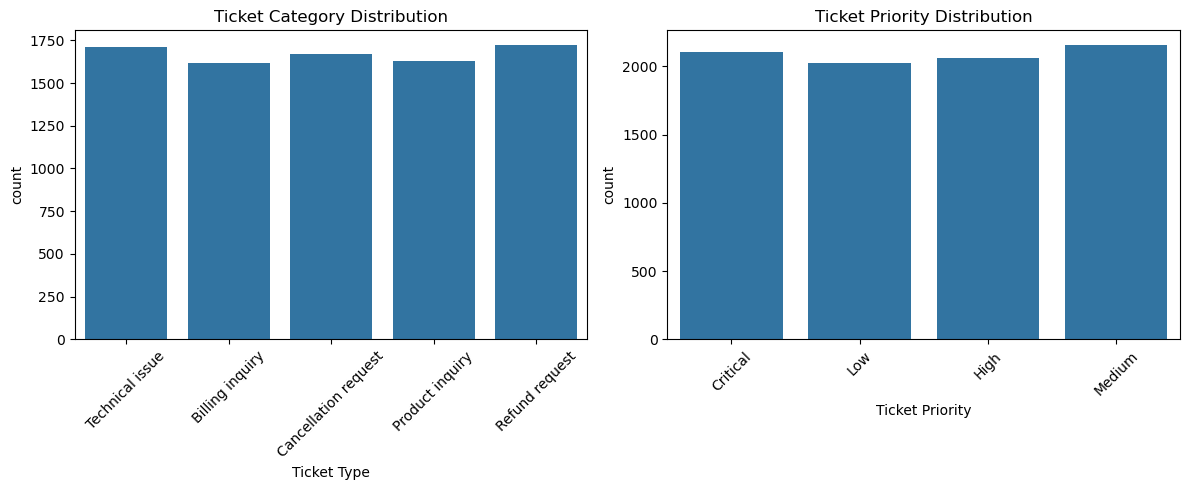

In [10]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=data, x='Ticket Type')
plt.title('Ticket Category Distribution')
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.countplot(data=data, x='Ticket Priority')
plt.title('Ticket Priority Distribution')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert ticket descriptions into numerical features
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X = vectorizer.fit_transform(data['Ticket Description'])

# Target variables
y_category = data['Ticket Type']
y_priority = data['Ticket Priority']

print("TF-IDF conversion completed!")
print("Feature matrix shape:", X.shape)
print("Number of categories:", y_category.nunique())
print("Number of priorities:", y_priority.nunique())

TF-IDF conversion completed!
Feature matrix shape: (8342, 5000)
Number of categories: 5
Number of priorities: 4


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Category classification model
X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    data['Ticket Description'],
    y_category,
    test_size=0.2,
    random_state=42,
    stratify=y_category
)

category_model = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('classifier', LogisticRegression(max_iter=1000))
])

category_model.fit(X_train_cat, y_train_cat)

# Priority classification model
X_train_pri, X_test_pri, y_train_pri, y_test_pri = train_test_split(
    data['Ticket Description'],
    y_priority,
    test_size=0.2,
    random_state=42,
    stratify=y_priority
)

priority_model = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('classifier', LogisticRegression(max_iter=1000))
])

priority_model.fit(X_train_pri, y_train_pri)

print("Both models trained successfully!")

Both models trained successfully!


In [13]:
# Category model predictions
y_pred_cat = category_model.predict(X_test_cat)

# Priority model predictions
y_pred_pri = priority_model.predict(X_test_pri)

# Category evaluation
print("========== CATEGORY CLASSIFICATION ==========")

print("Accuracy:",
      accuracy_score(y_test_cat, y_pred_cat))

print("\nClassification Report:")
print(classification_report(y_test_cat, y_pred_cat))

# Priority evaluation
print("\n========== PRIORITY CLASSIFICATION ==========")

print("Accuracy:",
      accuracy_score(y_test_pri, y_pred_pri))

print("\nClassification Report:")
print(classification_report(y_test_pri, y_pred_pri))

========== CATEGORY CLASSIFICATION ==========
Accuracy: 0.2049131216297184

Classification Report:
                      precision    recall  f1-score   support

     Billing inquiry       0.23      0.21      0.22       323
Cancellation request       0.19      0.18      0.18       334
     Product inquiry       0.20      0.19      0.19       326
      Refund request       0.20      0.21      0.20       344
     Technical issue       0.21      0.24      0.22       342

            accuracy                           0.20      1669
           macro avg       0.21      0.20      0.20      1669
        weighted avg       0.20      0.20      0.20      1669


========== PRIORITY CLASSIFICATION ==========
Accuracy: 0.237866986219293

Classification Report:
              precision    recall  f1-score   support

    Critical       0.23      0.21      0.22       421
        High       0.23      0.23      0.23       412
         Low       0.22      0.22      0.22       405
      Medium       0.26 

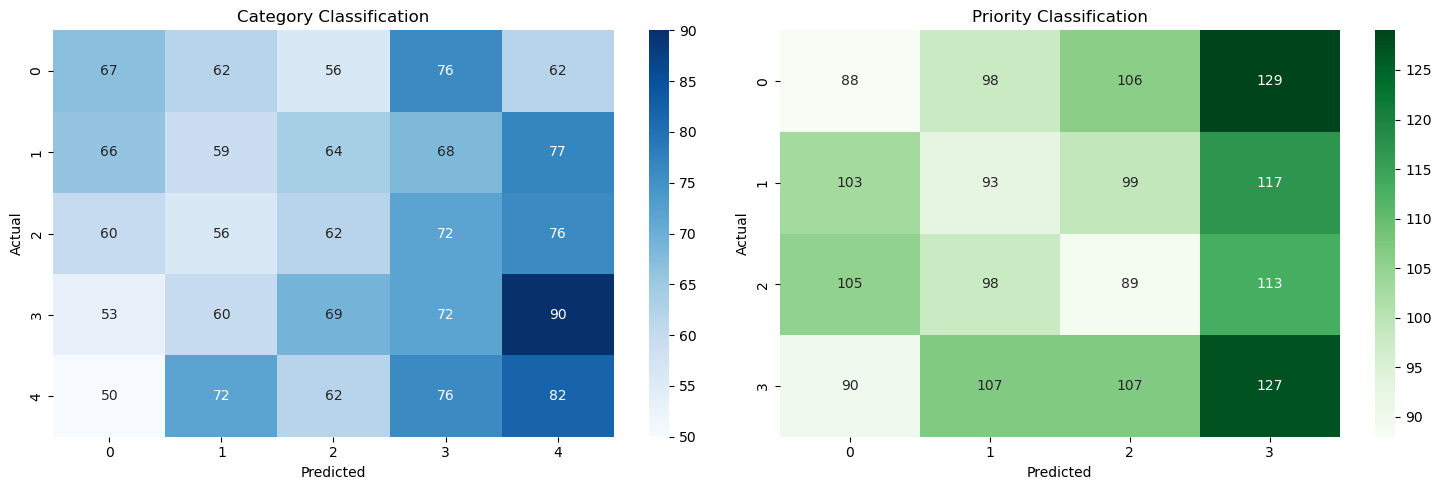

In [14]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Category confusion matrix
cm_cat = confusion_matrix(y_test_cat, y_pred_cat)

sns.heatmap(
    cm_cat,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title('Category Classification')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Priority confusion matrix
cm_pri = confusion_matrix(y_test_pri, y_pred_pri)

sns.heatmap(
    cm_pri,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1]
)

axes[1].set_title('Priority Classification')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [15]:
new_ticket = [
    "I was charged twice for my recent purchase "
    "and I need an immediate refund."
]

predicted_category = category_model.predict(new_ticket)[0]
predicted_priority = priority_model.predict(new_ticket)[0]

print("CUSTOMER SUPPORT TICKET RESULT")
print("--------------------------------")
print("Ticket:", new_ticket[0])
print("Predicted Category:", predicted_category)
print("Predicted Priority:", predicted_priority)

CUSTOMER SUPPORT TICKET RESULT
--------------------------------
Ticket: I was charged twice for my recent purchase and I need an immediate refund.
Predicted Category: Refund request
Predicted Priority: Critical


In [16]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# Combine subject and description
data['Combined_Text'] = (
    data['Ticket Subject'].astype(str) + " " +
    data['Ticket Description'].astype(str)
)

# Improved category model
X_train, X_test, y_train, y_test = train_test_split(
    data['Combined_Text'],
    data['Ticket Type'],
    test_size=0.2,
    random_state=42,
    stratify=data['Ticket Type']
)

improved_category_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ('classifier', LinearSVC())
])

improved_category_model.fit(X_train, y_train)

category_predictions = improved_category_model.predict(X_test)

print("Improved Category Model Accuracy:",
      accuracy_score(y_test, category_predictions))

print(classification_report(y_test, category_predictions))

KeyError: 'Ticket Subject'

In [17]:
# Recreate dataset with all required columns

data = df[
    ['Ticket Subject',
     'Ticket Description',
     'Ticket Type',
     'Ticket Priority']
].copy()

# Remove missing values
data.dropna(inplace=True)

# Combine subject and description
data['Combined_Text'] = (
    data['Ticket Subject'].astype(str) + " " +
    data['Ticket Description'].astype(str)
)

# Clean combined text
data['Combined_Text'] = data['Combined_Text'].apply(clean_text)

print("Combined dataset created successfully!")
display(data.head())

Combined dataset created successfully!


,Ticket Subject,Ticket Description,Ticket Type,Ticket Priority,Combined_Text
0,Product setup,I'm having an issue with the {product_purchase...,Technical issue,Critical,product setup im issue productpurchased please...
1,Peripheral compatibility,I'm having an issue with the {product_purchase...,Technical issue,Critical,peripheral compatibility im issue productpurch...
2,Network problem,I'm facing a problem with my {product_purchase...,Technical issue,Low,network problem im facing problem productpurch...
3,Account access,I'm having an issue with the {product_purchase...,Billing inquiry,Low,account access im issue productpurchased pleas...
4,Data loss,I'm having an issue with the {product_purchase...,Billing inquiry,Low,data loss im issue productpurchased please ass...


In [18]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    data['Combined_Text'],
    data['Ticket Type'],
    test_size=0.2,
    random_state=42,
    stratify=data['Ticket Type']
)

improved_category_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ('classifier', LinearSVC())
])

improved_category_model.fit(X_train, y_train)

category_predictions = improved_category_model.predict(X_test)

print("Category Model Accuracy:",
      accuracy_score(y_test, category_predictions))

print(classification_report(y_test, category_predictions))

Category Model Accuracy: 0.2024793388429752
                      precision    recall  f1-score   support

     Billing inquiry       0.20      0.19      0.20       327
Cancellation request       0.20      0.19      0.19       339
     Product inquiry       0.21      0.21      0.21       328
      Refund request       0.18      0.19      0.19       351
     Technical issue       0.23      0.23      0.23       349

            accuracy                           0.20      1694
           macro avg       0.20      0.20      0.20      1694
        weighted avg       0.20      0.20      0.20      1694



In [19]:
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    data['Combined_Text'],
    data['Ticket Priority'],
    test_size=0.2,
    random_state=42,
    stratify=data['Ticket Priority']
)

improved_priority_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ('classifier', LinearSVC())
])

improved_priority_model.fit(X_train_p, y_train_p)

priority_predictions = improved_priority_model.predict(X_test_p)

print("Priority Model Accuracy:",
      accuracy_score(y_test_p, priority_predictions))

print(classification_report(y_test_p, priority_predictions))

Priority Model Accuracy: 0.2514757969303424
              precision    recall  f1-score   support

    Critical       0.22      0.21      0.22       426
        High       0.27      0.28      0.28       417
         Low       0.22      0.22      0.22       413
      Medium       0.28      0.29      0.29       438

    accuracy                           0.25      1694
   macro avg       0.25      0.25      0.25      1694
weighted avg       0.25      0.25      0.25      1694



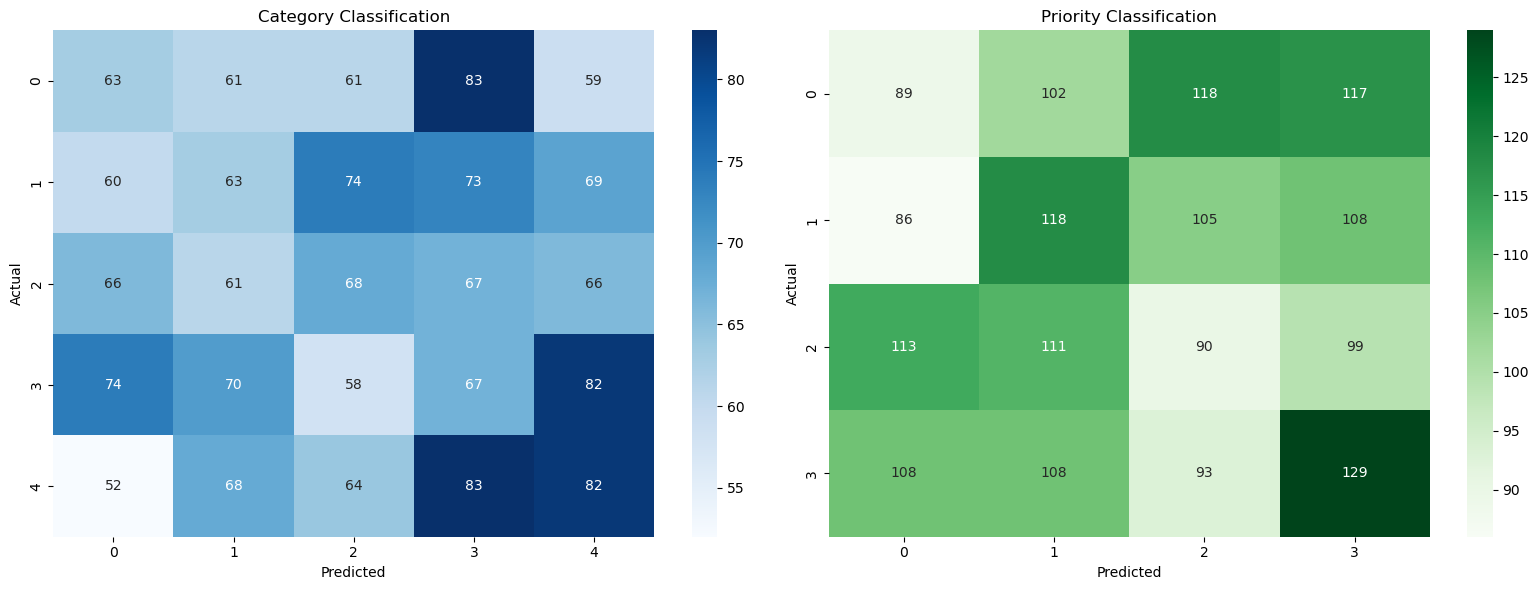

In [20]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Category confusion matrix
cm1 = confusion_matrix(y_test, category_predictions)

sns.heatmap(
    cm1,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title("Category Classification")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Priority confusion matrix
cm2 = confusion_matrix(y_test_p, priority_predictions)

sns.heatmap(
    cm2,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1]
)

axes[1].set_title("Priority Classification")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

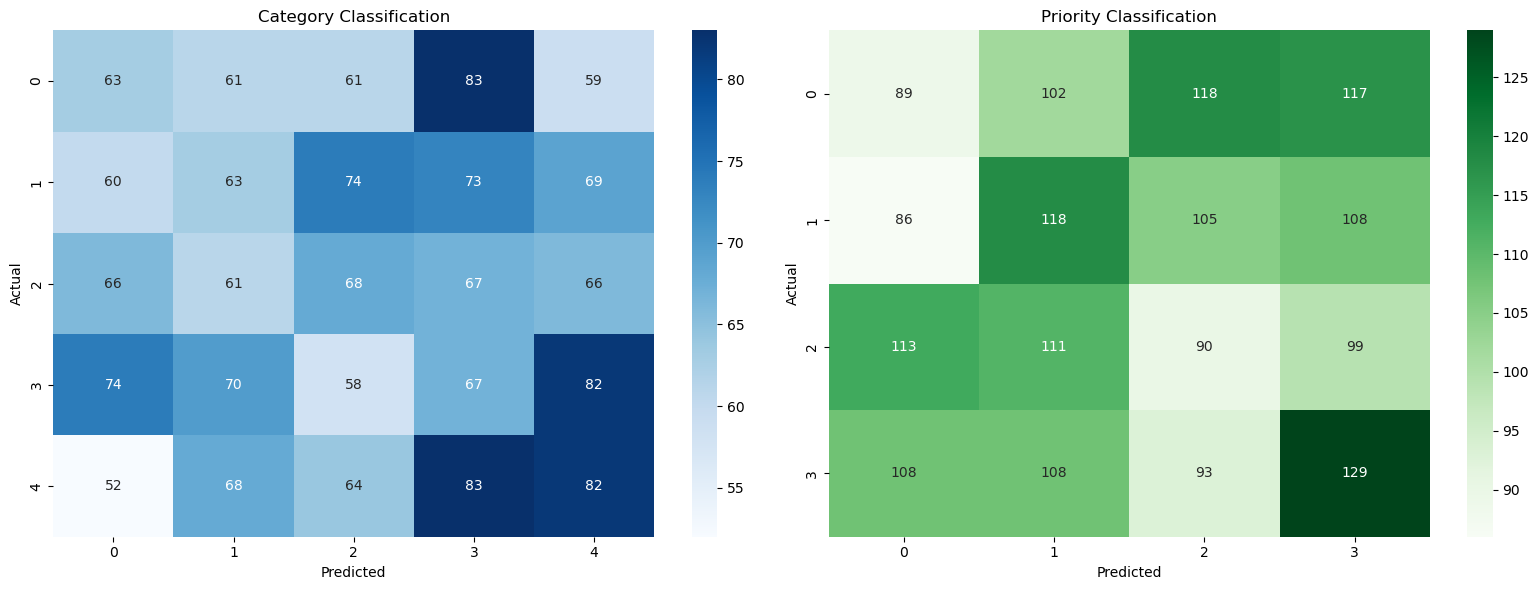

In [24]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Category confusion matrix
cm1 = confusion_matrix(y_test, category_predictions)

sns.heatmap(
    cm1,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title("Category Classification")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Priority confusion matrix
cm2 = confusion_matrix(y_test_p, priority_predictions)

sns.heatmap(
    cm2,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1]
)

axes[1].set_title("Priority Classification")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [25]:
import joblib
import os

os.makedirs("../outputs", exist_ok=True)

joblib.dump(
    improved_category_model,
    "../outputs/category_model.pkl"
)

joblib.dump(
    improved_priority_model,
    "../outputs/priority_model.pkl"
)

print("Both models saved successfully!")

Both models saved successfully!


In [26]:
from sklearn.metrics import classification_report

category_report = classification_report(
    y_test, category_predictions
)

priority_report = classification_report(
    y_test_p, priority_predictions
)

with open("../outputs/classification_report.txt", "w") as f:
    f.write("CATEGORY CLASSIFICATION REPORT\n")
    f.write(category_report)

    f.write("\n\nPRIORITY CLASSIFICATION REPORT\n")
    f.write(priority_report)

print("Classification reports saved successfully!")

Classification reports saved successfully!


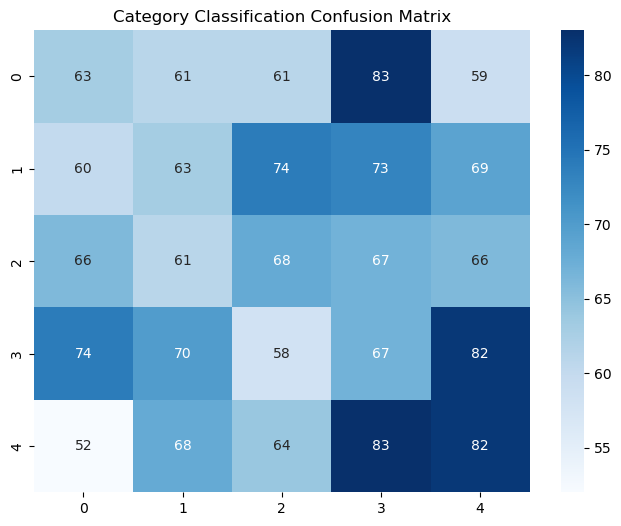

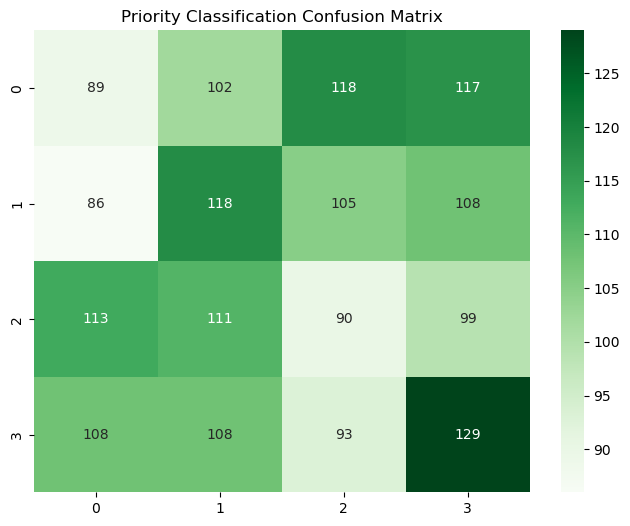

In [27]:
# Save category confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, category_predictions),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Category Classification Confusion Matrix")
plt.savefig("../outputs/category_confusion_matrix.png",
            bbox_inches="tight")
plt.show()


# Save priority confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test_p, priority_predictions),
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Priority Classification Confusion Matrix")
plt.savefig("../outputs/priority_confusion_matrix.png",
            bbox_inches="tight")
plt.show()